In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/pplonski/datasets-for-start/refs/heads/master/superstore-sales/superstore_dataset2011-2015.csv"

df = pd.read_csv(url, encoding="latin1")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,42433,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,...,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,Medium
1,22253,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,Medium
2,48883,HU-2011-1220,1/1/2011,5/1/2011,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,...,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,High
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,...,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,High
4,22255,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,Medium


In [3]:
# 1. Dataset size
print("Rows and columns:", df.shape)

# 2. Column names and data types
df.info()

# 3. Missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 4. Total duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Numerical summary
df.describe()

Rows and columns: (51290, 24)
<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  str    
 2   Order Date      51290 non-null  str    
 3   Ship Date       51290 non-null  str    
 4   Ship Mode       51290 non-null  str    
 5   Customer ID     51290 non-null  str    
 6   Customer Name   51290 non-null  str    
 7   Segment         51290 non-null  str    
 8   City            51290 non-null  str    
 9   State           51290 non-null  str    
 10  Country         51290 non-null  str    
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  str    
 13  Region          51290 non-null  str    
 14  Product ID      51290 non-null  str    
 15  Category        51290 non-null  str    
 16  Sub-Category    51290 non-null  str    
 17  Product Name

,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00000,9994.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,55190.379428,246.490581,3.476545,0.142908,28.610982,26.375915
std,14806.29199,32063.693350,487.565361,2.278766,0.212280,174.340972,57.296804
min,1.00000,1040.000000,0.444000,1.000000,0.000000,-6599.978000,0.000000
25%,12823.25000,23223.000000,30.758625,2.000000,0.000000,0.000000,2.610000
50%,25645.50000,56430.500000,85.053000,3.000000,0.000000,9.240000,7.790000
75%,38467.75000,90008.000000,251.053200,5.000000,0.200000,36.810000,24.450000
max,51290.00000,99301.000000,22638.480000,14.000000,0.850000,8399.976000,933.570000


In [4]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum().sum())

# Fill missing values
for column in df.columns:
    if df[column].dtype == "object":
        df[column] = df[column].fillna("Unknown")
    else:
        df[column] = df[column].fillna(df[column].median())

# Verify cleaning
print("\nMissing values after cleaning:", df.isnull().sum().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())

Missing values before cleaning:
41296


TypeError: Cannot perform reduction 'median' with string dtype

In [5]:
# Orders with sales greater than 500
high_sales = df[df["Sales"] > 500]

print("Orders with sales greater than 500:", len(high_sales))

high_sales.head()

Orders with sales greater than 500: 6752


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
23,44228,CA-2011-1800,1/3/2011,4/3/2011,First Class,TP-11415,Tom Prescott,Consumer,Toronto,Ontario,...,OFF-FEL-10001405,Office Supplies,Storage,"Fellowes File Cart, Industrial",551.160,4,0.0,71.6400,164.36,High
24,13130,ES-2011-1705541,1/3/2011,6/3/2011,Standard Class,TS-21370,Todd Sumrall,Corporate,Farnborough,England,...,FUR-BO-10000259,Furniture,Bookcases,"Safco Classic Bookcase, Traditional",1314.450,3,0.0,341.7300,150.40,High
25,48599,UP-2011-3730,1/3/2011,5/3/2011,Standard Class,RD-9900,Ruben Dartt,Consumer,Vinnytsya,Vinnytsya,...,TEC-LOG-10003896,Technology,Accessories,"Logitech Router, Erganomic",1470.780,6,0.0,264.6000,146.55,Medium
27,37844,CA-2011-113880,1/3/2011,5/3/2011,Standard Class,VF-21715,Vicky Freymann,Home Office,Elmhurst,Illinois,...,FUR-CH-10000863,Furniture,Chairs,Novimex Swivel Fabric Task Chair,634.116,6,0.3,-172.1172,70.05,High
29,13131,ES-2011-1705541,1/3/2011,6/3/2011,Standard Class,TS-21370,Todd Sumrall,Corporate,Farnborough,England,...,FUR-CH-10002830,Furniture,Chairs,"Office Star Rocking Chair, Red",704.550,5,0.0,288.7500,64.40,High


In [6]:
# Orders with negative profit
loss_orders = df[df["Profit"] < 0]

print("Orders with a loss:", len(loss_orders))

loss_orders.head()

Orders with a loss: 12544


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,...,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.0550,4.82,High
15,8484,US-2011-118892,1/2/2011,6/2/2011,Standard Class,DH-13075,Dave Hallsten,Corporate,San Miguelito,Panama,...,TEC-AC-10001221,Technology,Accessories,"Memorex Memory Card, USB",81.984,2,0.4,-19.1360,6.21,Medium
22,8482,US-2011-118892,1/2/2011,6/2/2011,Standard Class,DH-13075,Dave Hallsten,Corporate,San Miguelito,Panama,...,OFF-BI-10000719,Office Supplies,Binders,"Wilson Jones Hole Reinforcements, Clear",9.576,6,0.4,-0.9840,0.81,Medium
27,37844,CA-2011-113880,1/3/2011,5/3/2011,Standard Class,VF-21715,Vicky Freymann,Home Office,Elmhurst,Illinois,...,FUR-CH-10000863,Furniture,Chairs,Novimex Swivel Fabric Task Chair,634.116,6,0.3,-172.1172,70.05,High
34,39607,CA-2011-168312,1/3/2011,7/3/2011,Standard Class,GW-14605,Giulietta Weimer,Consumer,Houston,Texas,...,FUR-TA-10001866,Furniture,Tables,Bevis Round Conference Room Tables and Bases,376.509,3,0.3,-43.0296,32.70,Medium


In [7]:
category_summary = df.groupby("Category")[["Sales", "Profit"]].sum()

category_summary


,Sales,Profit
Category,,
Furniture,4.110874e+06,285204.72380
Office Supplies,3.787070e+06,518473.83430
Technology,4.744557e+06,663778.73318


In [8]:
region_summary = df.groupby("Region")[["Sales", "Profit"]].sum()

region_summary

,Sales,Profit
Region,,
Africa,7.837732e+05,88871.63100
Canada,6.692817e+04,17817.39000
Caribbean,3.242809e+05,34571.32104
Central,2.822303e+06,311403.98164
Central Asia,7.528266e+05,132480.18700
EMEA,8.061613e+05,43897.97100
East,6.787812e+05,91522.78000
North,1.248166e+06,194597.95252
North Asia,8.483098e+05,165578.42100


In [9]:
category_summary.sort_values(by="Sales", ascending=False)

,Sales,Profit
Category,,
Technology,4.744557e+06,663778.73318
Furniture,4.110874e+06,285204.72380
Office Supplies,3.787070e+06,518473.83430


In [10]:
# Create a region lookup table
region_managers = pd.DataFrame({
    "Region": ["Central", "East", "South", "West"],
    "Manager": ["Alice", "Bob", "Charlie", "David"]
})

# Join the sales data with the region managers
df_joined = pd.merge(df, region_managers, on="Region", how="left")

df_joined[["Region", "Manager", "Sales", "Profit"]].head()

,Region,Manager,Sales,Profit
0,Africa,NaN,408.300,106.140
1,Oceania,NaN,120.366,36.036
2,EMEA,NaN,66.120,29.640
3,North,NaN,44.865,-26.055
4,Oceania,NaN,113.670,37.770


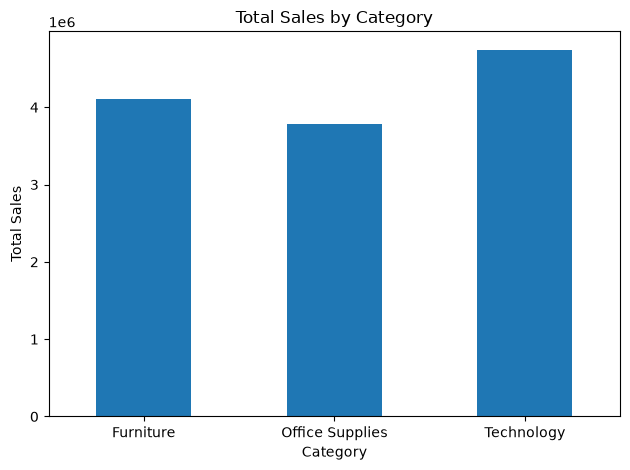

In [11]:
category_summary = df.groupby("Category")["Sales"].sum()

category_summary.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

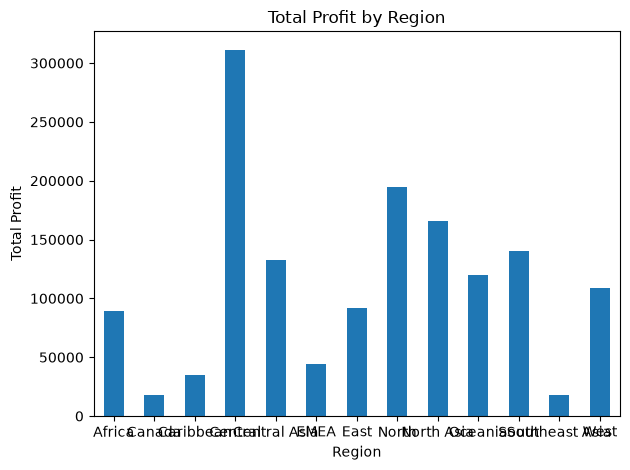

In [12]:
region_summary = df.groupby("Region")["Profit"].sum()

region_summary.plot(kind="bar")

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# 1. Which product category has the highest sales?
print("Sales by category:")
print(df.groupby("Category")["Sales"].sum().sort_values(ascending=False))

# 2. Which region generates the highest profit?
print("\nProfit by region:")
print(df.groupby("Region")["Profit"].sum().sort_values(ascending=False))

# 3. Which product sub-category generates the highest sales?
print("\nSales by sub-category:")
print(df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False))

# 4. Which customer segment generates the highest sales?
print("\nSales by customer segment:")
print(df.groupby("Segment")["Sales"].sum().sort_values(ascending=False))

# 5. Which ship mode has the highest average shipping cost?
print("\nAverage shipping cost by ship mode:")
print(df.groupby("Ship Mode")["Shipping Cost"].mean().sort_values(ascending=False))

Sales by category:
Category
Technology         4.744557e+06
Furniture          4.110874e+06
Office Supplies    3.787070e+06
Name: Sales, dtype: float64

Profit by region:
Region
Central           311403.98164
North             194597.95252
North Asia        165578.42100
South             140355.76618
Central Asia      132480.18700
Oceania           120089.11200
West              108418.44890
East               91522.78000
Africa             88871.63100
EMEA               43897.97100
Caribbean          34571.32104
Southeast Asia     17852.32900
Canada             17817.39000
Name: Profit, dtype: float64

Sales by sub-category:
Sub-Category
Phones         1.706824e+06
Copiers        1.509436e+06
Chairs         1.501682e+06
Bookcases      1.466572e+06
Storage        1.127086e+06
Appliances     1.011064e+06
Machines       7.790601e+05
Tables         7.570419e+05
Accessories    7.492370e+05
Binders        4.619115e+05
Furnishings    3.855783e+05
Art            3.720920e+05
Paper          2.